# Frugal NLP Benchmark — EDA, learning curves and SLM vs LLM analysis
Everything here calls `frugal_nlp.py`, so the notebook follows the same reproducible protocol (fixed seeds, fixed test sample, SQLite registry, CodeCarbon energy).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import logging, frugal_nlp as fn
fn.log.setLevel(logging.WARNING); logging.getLogger().setLevel(logging.ERROR)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)
fn.env_snapshot()

{'python': '3.11.9',
 'os': 'Windows-10-10.0.26200-SP0',
 'torch': '2.6.0+cu124',
 'transformers': '5.22.0',
 'peft': '0.21.2',
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3050 A Laptop GPU'}

## 1. Exploratory data analysis
Class balance, text length and how much PII each corpus contains (what would leak if raw text were sent to an external LLM).

In [2]:
rows, frames = [], {}
for uc in fn.TASKS:
    pool, test, labels, _ = fn._frames(uc)
    frames[uc] = (pool, labels)
    sample = pool.sample(min(3000, len(pool)), random_state=0)
    pii = sample.text.map(lambda t: fn.redact(t)[1])
    rows.append({'use_case': uc, 'train_pool': len(pool), 'test_pool': len(test), 'classes': len(labels),
                 'median_words': int(sample.text.str.split().str.len().median()),
                 'pct_texts_with_pii': round(100 * (pii > 0).mean(), 2)})
pd.DataFrame(rows)

2026-10-29 19:38:57,489 WARNING Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


,use_case,train_pool,test_pool,classes,median_words,pct_texts_with_pii
0,sentiment,67349,872,2,7,0.0
1,topic,120000,7600,4,38,1.6
2,spam,4459,1115,2,12,7.9


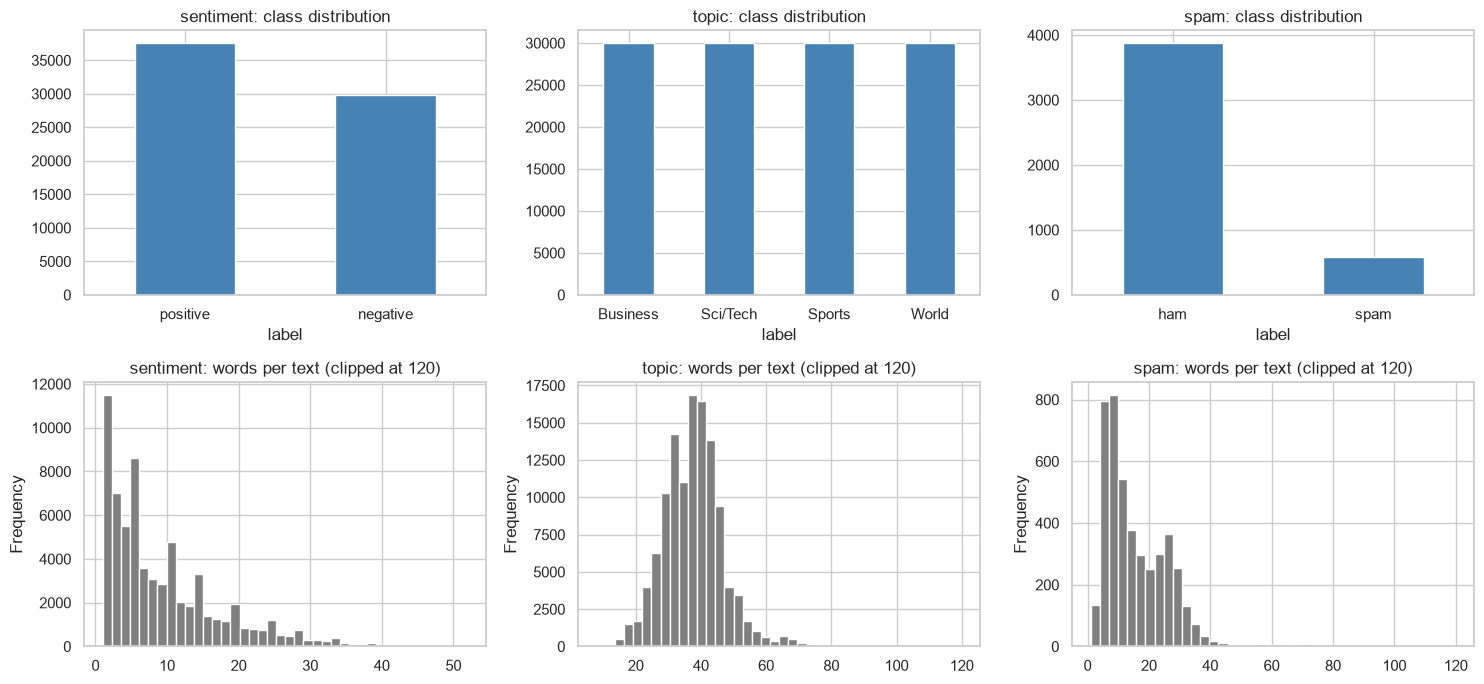

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, (uc, (pool, labels)) in enumerate(frames.items()):
    pool.label.map(dict(enumerate(labels))).value_counts().plot.bar(ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{uc}: class distribution'); axes[0, i].tick_params(axis='x', rotation=0)
    pool.text.str.split().str.len().clip(upper=120).plot.hist(bins=40, ax=axes[1, i], color='gray')
    axes[1, i].set_title(f'{uc}: words per text (clipped at 120)')
plt.tight_layout()

SST-2 and AG News are balanced; SMS spam is imbalanced (~13 % spam), so **macro-F1** is the main metric. Texts are short, so `max_len=128` covers almost everything. The SMS corpus contains phone numbers and URLs, which is why remote LLM calls go through `fn.redact`.

In [4]:
for t in frames['spam'][0].text.head(400):
    clean, n = fn.redact(t)
    if n: print('RAW  :', t[:110]); print('CLEAN:', clean[:110]); break

RAW  : WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906
CLEAN: WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call [PHO


## 2. Learning curve: how few annotations are enough?
LoRA on DistilBERT with 8 → 64 labels per class (3 seeds each for the smallest budgets would be ideal; one seed keeps this notebook fast).

In [5]:
curve = []
for uc in ['sentiment', 'topic', 'spam']:
    for n in [8, 16, 32, 64]:
        r = fn.create_model(fn.TrainConfig(use_case=uc, n_per_class=n), n_test=300)
        curve.append({'use_case': uc, 'n_per_class': n, 'macro_f1': r['evaluation']['macro_f1'],
                      'train_wh': r['train_wh'], 'train_s': r['train_seconds']})
curve = pd.DataFrame(curve); curve

,use_case,n_per_class,macro_f1,train_wh,train_s
0,sentiment,8,0.807065,0.03076,1.13
1,sentiment,16,0.809744,0.03421,1.52
2,sentiment,32,0.819968,0.06001,2.95
3,sentiment,64,0.833304,0.13997,5.75
4,topic,8,0.779998,0.03889,1.57
5,topic,16,0.858135,0.08373,3.10
6,topic,32,0.857203,0.16601,6.22
7,topic,64,0.872785,0.34246,12.57
8,spam,8,0.750176,0.02761,0.85
9,spam,16,0.952948,0.04547,1.62


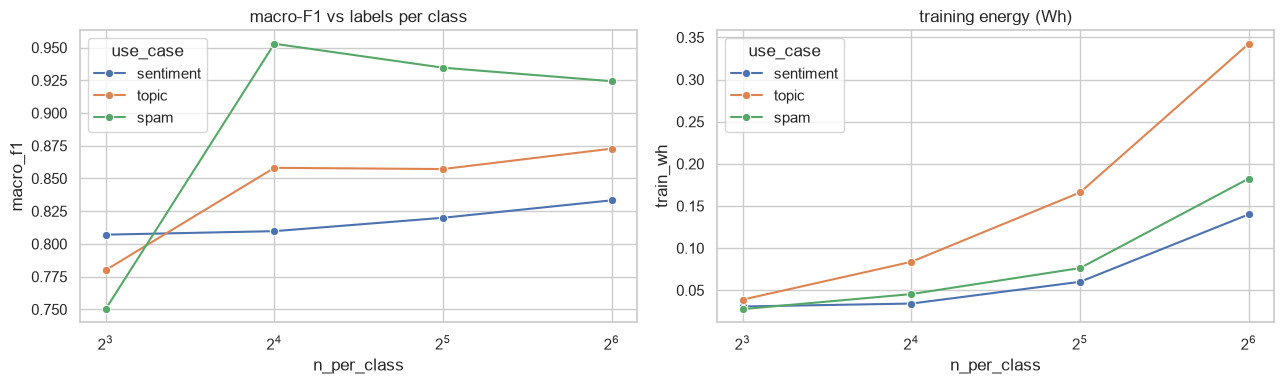

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(curve, x='n_per_class', y='macro_f1', hue='use_case', marker='o', ax=ax[0])
ax[0].set_xscale('log', base=2); ax[0].set_title('macro-F1 vs labels per class')
sns.lineplot(curve, x='n_per_class', y='train_wh', hue='use_case', marker='o', ax=ax[1])
ax[1].set_xscale('log', base=2); ax[1].set_title('training energy (Wh)')
plt.tight_layout()

## 3. Reproducibility check
Same config + same seed must give the same model id and the same score.

In [7]:
a = fn.create_model(fn.TrainConfig(use_case='sentiment', n_per_class=16), n_test=300)
b = fn.create_model(fn.TrainConfig(use_case='sentiment', n_per_class=16), n_test=300)
print(a['model_id'] == b['model_id'], a['evaluation']['macro_f1'], b['evaluation']['macro_f1'])

True 0.809744 0.809744


## 4. Small models vs LLMs (from the SQLite registry)
Run `python frugal_nlp.py benchmark` first; this section only reads the registry with SQL.

In [8]:
lb = fn.leaderboard()
best = (lb.assign(family=lb.kind.where(lb.kind != 'slm', 'slm (LoRA)'))
          .sort_values('macro_f1', ascending=False).groupby(['use_case', 'family']).head(1))
best[['use_case', 'family', 'model_id', 'n_train', 'macro_f1', 'accuracy', 'wh_per_1k', 'latency_ms',
      'train_wh', 'data_left_premises']]

,use_case,family,model_id,n_train,macro_f1,accuracy,wh_per_1k,latency_ms,train_wh,data_left_premises
0,sentiment,llm-gemini,llm-gemini-gemini-3.5-flash-lite-sentiment,0,0.9700,0.9700,19.4602,803.12,0.0000,1
11,spam,llm-gemini,llm-gemini-gemini-3.5-flash-lite-spam,0,0.9664,0.9833,15.3489,445.89,0.0000,1
12,spam,slm (LoRA),slm-spam-distilbert-base-uncased-32pc-1e84cf,64,0.9593,0.9800,0.0576,1.53,0.0754,0
1,sentiment,llm-local,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0,0.9033,0.9033,0.2344,9.64,0.0000,0
21,topic,llm-gemini,llm-gemini-gemini-3.5-flash-lite-topic,0,0.8911,0.8833,16.4707,557.19,0.0000,1
22,topic,slm (LoRA),slm-topic-bge-base-en-v1.5-32pc-6aae4c,128,0.8828,0.8767,0.1073,3.05,0.3467,0
2,sentiment,slm (LoRA),slm-sentiment-bge-base-en-v1.5-32pc-73a641,64,0.8499,0.8500,0.0617,1.99,0.1088,0
20,spam,llm-local,llm-local-Qwen2.5-0.5B-Instruct-spam,0,0.4880,0.8667,0.2423,10.14,0.0000,0
29,topic,llm-local,llm-local-Qwen2.5-0.5B-Instruct-topic,0,0.4284,0.5033,0.3316,14.74,0.0000,0


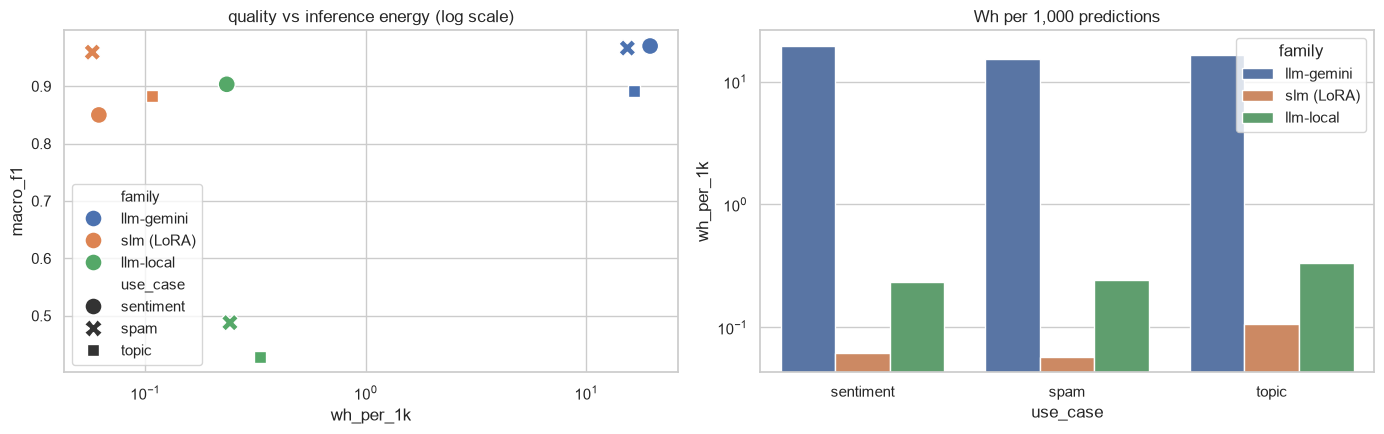

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(best, x='wh_per_1k', y='macro_f1', hue='family', style='use_case', s=150, ax=ax[0])
ax[0].set_xscale('log'); ax[0].set_title('quality vs inference energy (log scale)')
sns.barplot(best, x='use_case', y='wh_per_1k', hue='family', ax=ax[1]); ax[1].set_yscale('log')
ax[1].set_title('Wh per 1,000 predictions'); plt.tight_layout()

## 5. When does training pay off?
The small model spends energy once on training; the break-even is the number of predictions after which SLM (train + inference) is cheaper than the LLM.

In [10]:
pd.concat([fn.breakeven(uc).assign(use_case=uc) for uc in lb.use_case.unique()], ignore_index=True)

,slm,llm,slm_train_wh,breakeven_predictions,energy_ratio_llm_over_slm,use_case
0,slm-sentiment-bge-base-en-v1.5-32pc-73a641,llm-gemini-gemini-3.5-flash-lite-sentiment,0.1088,6,315.4,sentiment
1,slm-sentiment-bge-base-en-v1.5-32pc-73a641,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0.1088,630,3.8,sentiment
2,slm-sentiment-bge-small-en-v1.5-64pc-cbe69d,llm-gemini-gemini-3.5-flash-lite-sentiment,0.1400,8,322.7,sentiment
3,slm-sentiment-bge-small-en-v1.5-64pc-cbe69d,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0.1400,805,3.9,sentiment
4,slm-sentiment-bge-small-en-v1.5-32pc-a0e6bb,llm-gemini-gemini-3.5-flash-lite-sentiment,0.0711,4,1138.0,sentiment
5,slm-sentiment-bge-small-en-v1.5-32pc-a0e6bb,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0.0711,328,13.7,sentiment
6,slm-sentiment-bge-small-en-v1.5-32pc-1e03a9,llm-gemini-gemini-3.5-flash-lite-sentiment,0.1062,6,377.9,sentiment
7,slm-sentiment-bge-small-en-v1.5-32pc-1e03a9,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0.1062,581,4.6,sentiment
8,slm-sentiment-bge-small-en-v1.5-32pc-025c43,llm-gemini-gemini-3.5-flash-lite-sentiment,0.0600,4,442.3,sentiment
9,slm-sentiment-bge-small-en-v1.5-32pc-025c43,llm-local-Qwen2.5-0.5B-Instruct-sentiment,0.0600,316,5.3,sentiment


## 6. SQL view of the registry
The registry is plain SQLite; any BI tool can read it.

In [11]:
fn.query('''SELECT m.kind, COUNT(*) AS n_models, ROUND(AVG(e.macro_f1),3) AS avg_f1,
                   ROUND(SUM(m.train_kwh)*1000,3) AS total_train_wh, ROUND(AVG(e.wh_per_1k),4) AS avg_wh_per_1k
            FROM models m JOIN evaluations e USING(model_id) GROUP BY m.kind''')

,kind,n_models,avg_f1,total_train_wh,avg_wh_per_1k
0,llm-gemini,3,0.942,0.000,17.0933
1,llm-local,3,0.607,0.000,0.2694
2,slm,50,0.854,4.993,0.0427
